## WorldView Full-Scene DEMs: Hillshades of Good and Poor Results (Atlanta and UCSD)

The full-scene benchmarks score DEMs by numbers:
- [Atlanta](https://asp-plot.readthedocs.io/en/latest/examples/notebooks/worldview_spacenet_atlanta_full_benchmark.html): 21 DEMs from five same-pass WorldView-2 strips;
- [UCSD](https://asp-plot.readthedocs.io/en/latest/examples/notebooks/worldview_spacenet_ucsd_full_benchmark.html): 18 DEMs from five multi-date WorldView-3 scenes;
- [3DEP lidar](https://asp-plot.readthedocs.io/en/latest/examples/notebooks/worldview_spacenet_lidar_comparison.html): the same 39 DEMs on open ground.

This notebook shows what those numbers look like. For each site, four DEMs span the range:

| site | DEM | why |
|---|---|---|
| Atlanta | raw pair 10-21 (31.7°) | best on ICESat-2 and on lidar |
| Atlanta | 6 pairs > 15°, `dem_mosaic` | the best DEM with near-full coverage |
| Atlanta | all 10 pairs, plain `dem_mosaic` | what averaging in the narrow pairs costs |
| Atlanta | pair 13-16 (4.5°) | worst on lidar |
| UCSD | pair nadir-n16 (16.8°) | best on lidar |
| UCSD | all 10 pairs, plain `dem_mosaic` | best on ICESat-2 |
| UCSD | raw pair n24-n08 (34.0°) | widest pair, lowest coverage |
| UCSD | pair n15-n16 (8.0°) | worst mapprojected pair |

Unless marked raw, every pair and blend is mapprojected onto COP30.

For each site, the notebook shows:
- **Full scene:** a hillshade of each DEM, computed at full resolution and then averaged down for display, so the texture of noise survives. Voids inside each DEM's footprint are orange.
- **Detail windows:** 1.5 km squares at full resolution, next to the bare-earth 3DEP lidar of the same ground.
- **Terrain:** the slope distribution of the lidar and of each DEM over their common area, and the land cover there, with the share of ICESat-2 points on each class.

Every DEM is shown as registered to the lidar: the benchmark's ICESat-2-aligned copy, moved by its east/north shift to the lidar from the [lidar notebook's](https://asp-plot.readthedocs.io/en/latest/examples/notebooks/worldview_spacenet_lidar_comparison.html) registration, without resampling. All panels of a window then show the same ground. Hillshades are lit from the northwest (azimuth 315°, altitude 45°).

In [1]:
import glob, os, warnings
import numpy as np, pandas as pd, rasterio as rio, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from matplotlib.patches import Patch, Rectangle
from matplotlib_scalebar.scalebar import ScaleBar
from rasterio.warp import reproject, Resampling
from rasterio.windows import from_bounds
from scipy.ndimage import binary_fill_holes

SITES = {
    "Atlanta": dict(
        root="/nobackup/bpurint1/data/atlanta", fb="/nobackup/bpurint1/data/atlanta/WV/20091222_spacenet/full_benchmark",
        picks={"raw_pair_10-21_31.7": "raw pair 10-21 (31.7°)", "6_pairs_15_mosaic": "6 pairs > 15°, blend",
               "10_pairs_mosaic": "all 10 pairs, plain blend", "pair_13-16_4.5": "pair 13-16 (4.5°)"},
        windows={"downtown": (741930, 3738279), "airport, in the cropped study's window": (738517, 3724995)},
        decimate=8),
    "UCSD": dict(
        root="/nobackup/bpurint1/data/ucsd", fb="/nobackup/bpurint1/data/ucsd/WV3/core3d/full_benchmark",
        picks={"pair_nadir-n16_16.8": "pair nadir-n16 (16.8°)", "10_pairs_mosaic": "all 10 pairs, plain blend",
               "raw_pair_n24-n08_34.0": "raw pair n24-n08 (34.0°)", "pair_n15-n16_8.0": "pair n15-n16 (8.0°)"},
        windows={"UCSD campus": (477830, 3637898), "canyons, in the cropped study's window (crop A)": (477500, 3633500)},
        decimate=10),
}
HALF = 750  # detail windows are 1.5 km squares
VOID = "#f28e2b"
LS = LightSource(azdeg=315, altdeg=45)

for s in SITES.values():
    s["grid"] = f"{s['root']}/lidar/grid_recipe"
    s["reg"] = pd.read_csv(f"{s['root']}/lidar/register/registration.csv").set_index("label")
    s["lidar_nmad"] = pd.read_csv(f"{s['root']}/lidar/compare_lidarreg/stats.csv").set_index("label").shared_nmad
    s["is2_nmad"] = pd.read_csv(f"{s['root']}/lidar/register/is2_vertical_only.csv").set_index("label").nmad_pc_align

def dem_source(s, label):
    """(path, east shift, north shift): the benchmark's ICESat-2-aligned DEM and its registration shift to the lidar."""
    fn, = glob.glob(f"{s['fb']}/dem_benchmark/{label}/*_pc_align_translated.tif")
    r = s["reg"].loc[label]
    return fn, r.east_m, r.north_m

def read_masked(ds, **kw):
    return ds.read(1, masked=True, **kw).astype(np.float32).filled(np.nan)

def shade(z, res):
    """Hillshade in [0, 1] with NaN where z (or a neighbour) is NaN."""
    h = LS.hillshade(np.nan_to_num(z, nan=np.nanmedian(z)), dx=res, dy=res)
    nan = ~np.isfinite(z)
    nan[1:] |= nan[:-1].copy(); nan[:-1] |= nan[1:].copy(); nan[:, 1:] |= nan[:, :-1].copy(); nan[:, :-1] |= nan[:, 1:].copy()
    h[nan] = np.nan
    return h

def block_mean(a, f):
    h, w = (a.shape[0] // f) * f, (a.shape[1] // f) * f
    b = a[:h, :w].reshape(h // f, f, w // f, f)
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # all-NaN blocks
        m = np.nanmean(b, axis=(1, 3))
        m[np.isnan(b).mean(axis=(1, 3)) > 0.5] = np.nan
    return m

def show_shade(ax, h, extent, void_inside=None, vmin=0, vmax=1):
    """Grey hillshade; NaN cells inside the footprint (void_inside) in orange, outside it white."""
    if void_inside is not None:
        ax.imshow(np.where(void_inside & np.isnan(h), 1.0, np.nan), cmap=plt.matplotlib.colors.ListedColormap([VOID]),
                  extent=extent, interpolation="nearest")
    ax.imshow(h, cmap="gray", vmin=vmin, vmax=vmax, extent=extent, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])

def title(s, label, name, void_pct=None):
    t = f"{name}\nICESat-2 NMAD {s['is2_nmad'][label]:.2f} m · lidar NMAD {s['lidar_nmad'][label]:.2f} m"
    return t + (f" · voids {void_pct:.1f} %" if void_pct is not None else "")

print(pd.DataFrame([{"site": n, "DEM": name, "ICESat-2 NMAD, stable terrain (m)": s["is2_nmad"][l],
                     "lidar NMAD, open ground, registered (m)": s["lidar_nmad"][l],
                     "registration shift east, north (m)": f"{s['reg'].east_m[l]:+.2f}, {s['reg'].north_m[l]:+.2f}"}
                    for n, s in SITES.items() for l, name in s["picks"].items()]).round(2).to_string(index=False))

   site                       DEM  ICESat-2 NMAD, stable terrain (m)  lidar NMAD, open ground, registered (m) registration shift east, north (m)
Atlanta    raw pair 10-21 (31.7°)                               0.76                                     0.56                       +0.30, +3.26
Atlanta      6 pairs > 15°, blend                               0.86                                     0.71                       +0.29, +2.24
Atlanta all 10 pairs, plain blend                               1.08                                     0.97                       -0.10, +2.13
Atlanta         pair 13-16 (4.5°)                               1.60                                     1.48                       +0.66, +2.38
   UCSD    pair nadir-n16 (16.8°)                               1.10                                     0.69                       -3.38, +1.86
   UCSD all 10 pairs, plain blend                               1.03                                     0.78                     

### Full scenes

Each panel is one DEM over its whole footprint, hillshaded at full resolution (1.9 m at Atlanta, 1.2 m at UCSD) and averaged in 8 × 8 (Atlanta) or 10 × 10 (UCSD) blocks for display. Noise shows as a grainy grey, voids inside the footprint as orange; voids that reach the edge of the footprint stay white. The grey scale is stretched to the 1st–99th percentile of each site's best DEM, the same for all four panels. The titles give each DEM's voids as a share of its footprint, at full resolution. The boxes are the detail windows below.

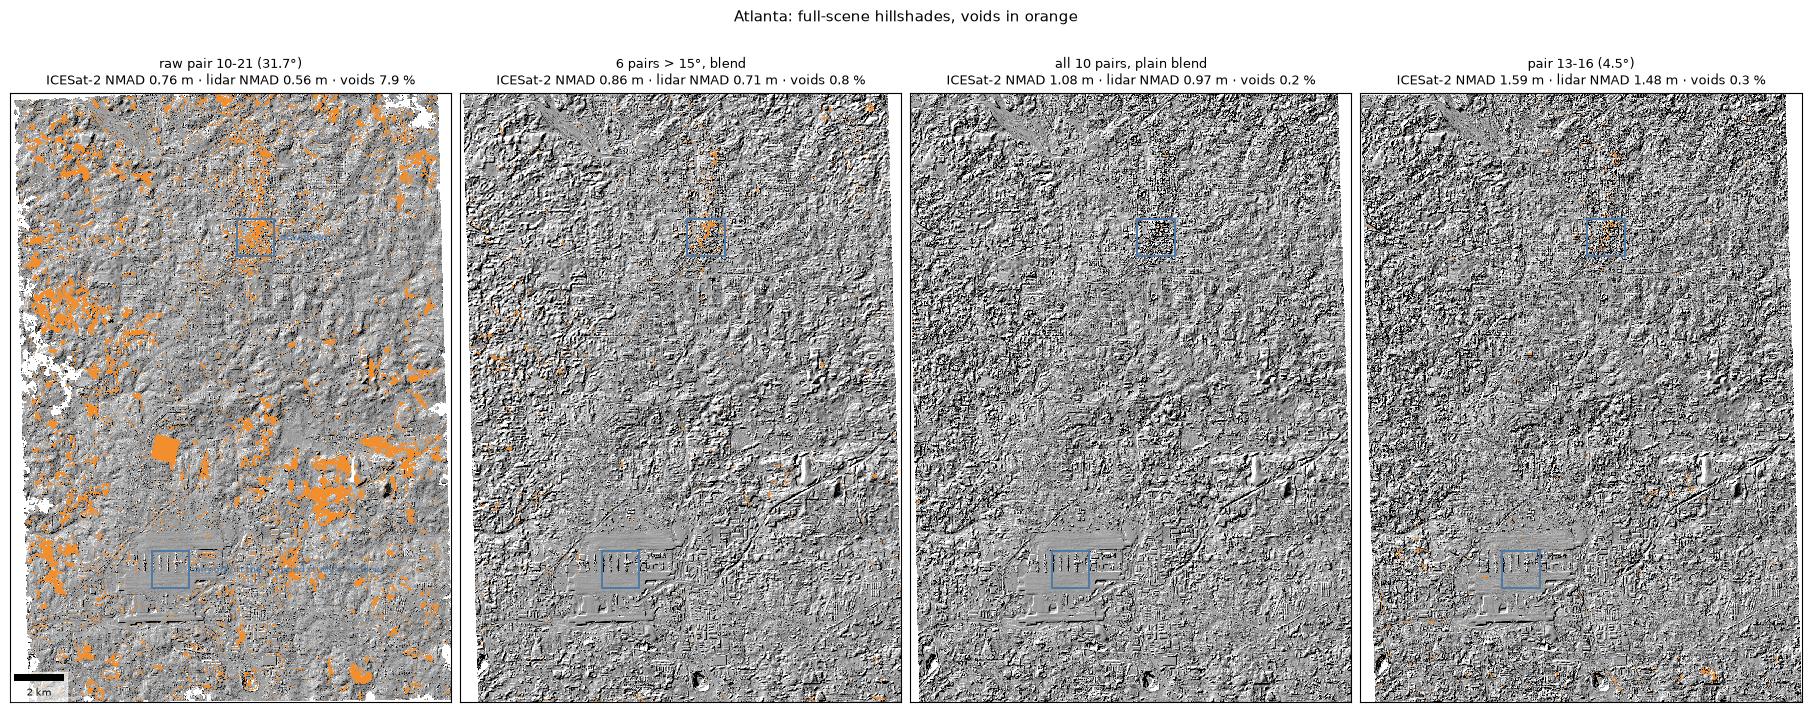

In [2]:
def full_scene(name):
    s = SITES[name]; f = s["decimate"]
    fig, axs = plt.subplots(1, 4, figsize=(18, 7.6 if name == "Atlanta" else 5.6), sharex=True, sharey=True,
                            layout="constrained")
    panels = []
    for label in s["picks"]:
        fn, de, dn = dem_source(s, label)
        with rio.open(fn) as ds:
            z = read_masked(ds); res = ds.res[0]; b = ds.bounds
        valid = np.isfinite(z); footprint = binary_fill_holes(valid)
        void_pct = 100 * (footprint & ~valid).sum() / footprint.sum()
        h = block_mean(shade(z, res), f); del z, valid, footprint
        extent = [b.left + de, b.left + de + h.shape[1] * res * f, b.top + dn - h.shape[0] * res * f, b.top + dn]
        panels.append((label, h, extent, void_pct))
    vmin, vmax = np.nanpercentile(panels[0][1], [1, 99])
    for ax, (label, h, extent, void_pct) in zip(axs, panels):
        dem_name = s["picks"][label]
        show_shade(ax, h, extent, void_inside=binary_fill_holes(np.isfinite(h)), vmin=vmin, vmax=vmax)
        for wname, (x, y) in s["windows"].items():
            ax.add_patch(Rectangle((x - HALF, y - HALF), 2 * HALF, 2 * HALF, fill=False, ec="#4e79a7", lw=1.4))
        ax.set_title(title(s, label, dem_name, void_pct), fontsize=9)
    for wname, (x, y) in s["windows"].items():
        axs[0].annotate(wname, (x + HALF, y), xytext=(4, 0), textcoords="offset points", fontsize=7, color="#4e79a7",
                        va="center")
    axs[0].add_artist(ScaleBar(1, "m", location="lower left", box_alpha=0.6, font_properties={"size": 7}))
    fig.suptitle(f"{name}: full-scene hillshades, voids in orange", fontsize=11)
    return fig

full_scene("Atlanta");

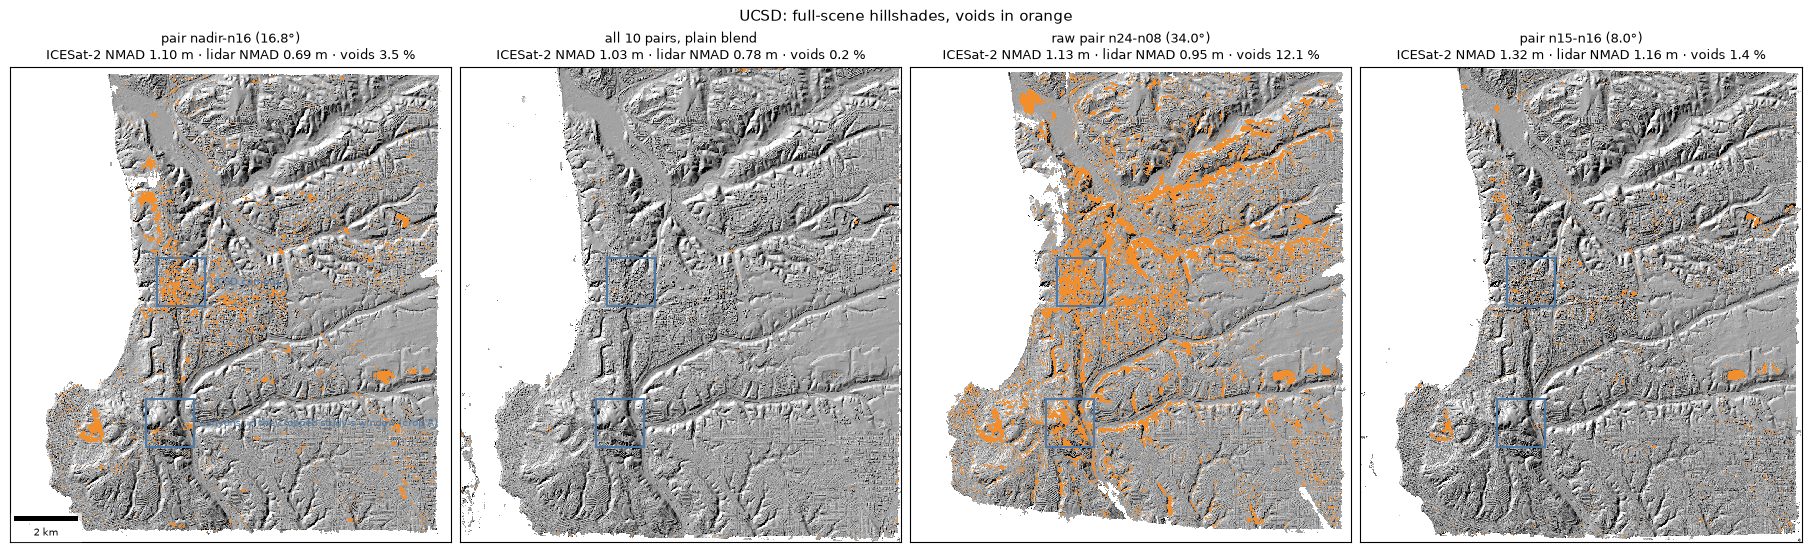

In [3]:
full_scene("UCSD");

### Detail windows

1.5 km squares at full resolution. The first panel is the 3DEP lidar, a bare-earth model: buildings and trees are removed, so it shows the ground the DEMs stand on, not the surface they should reproduce. Atlanta's lidar is from 2018–20, nine to ten years after the 2009 imagery; UCSD's was flown in the same weeks as its images.

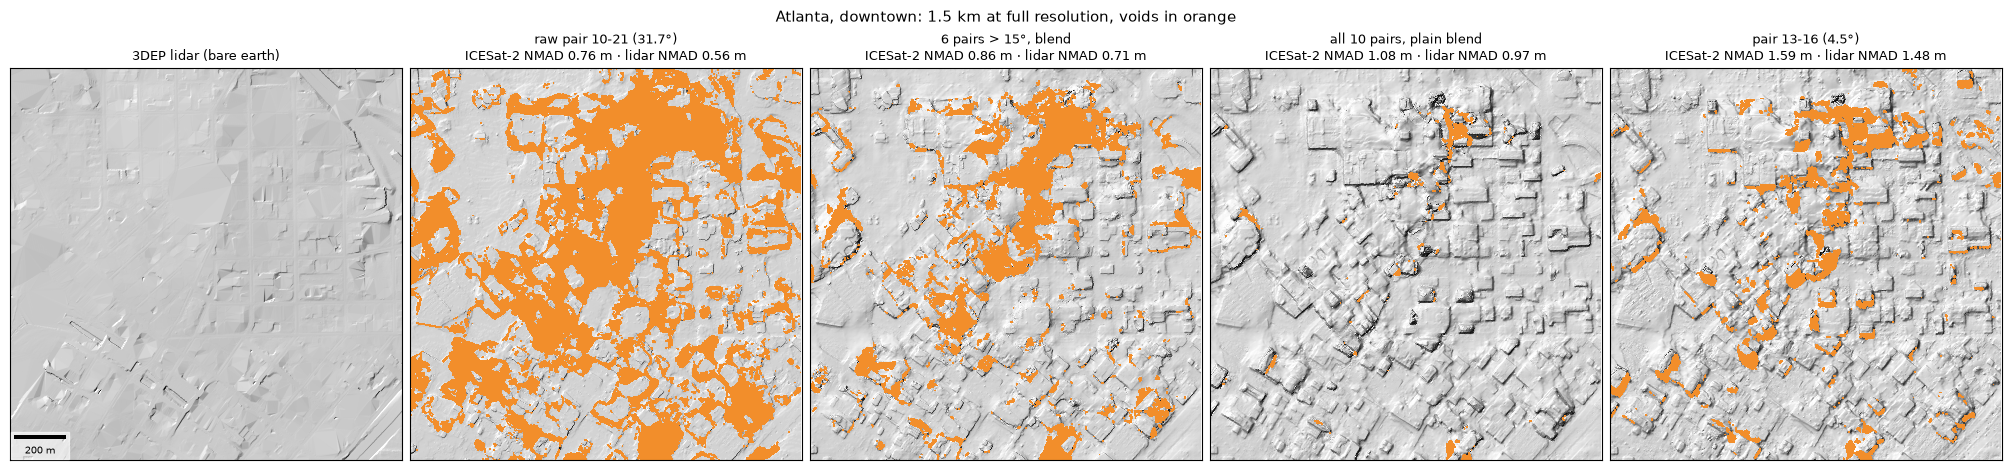

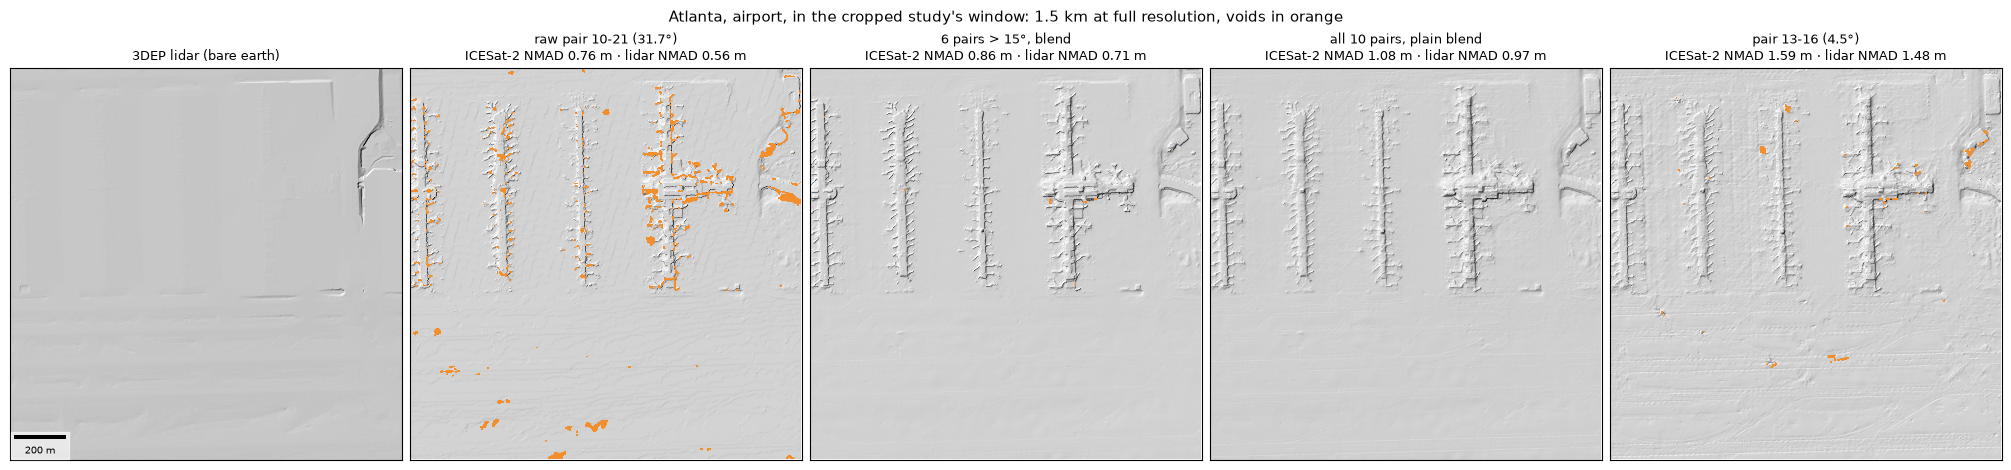

In [4]:
def detail(name, wname):
    s = SITES[name]; x, y = s["windows"][wname]
    box = (x - HALF, y - HALF, x + HALF, y + HALF)
    fig, axs = plt.subplots(1, 5, figsize=(20, 4.6), layout="constrained")
    with rio.open(f"{s['grid']}/lidar.tif") as ds:
        z = read_masked(ds, window=from_bounds(*box, ds.transform)); res = ds.res[0]
    show_shade(axs[0], shade(z, res), [box[0], box[2], box[1], box[3]], void_inside=np.ones(z.shape, bool))
    axs[0].set_title("3DEP lidar (bare earth)", fontsize=9)
    for ax, (label, dem_name) in zip(axs[1:], s["picks"].items()):
        fn, de, dn = dem_source(s, label)
        with rio.open(fn) as ds:
            win = from_bounds(box[0] - de, box[1] - dn, box[2] - de, box[3] - dn, ds.transform).round_offsets().round_lengths()
            z = read_masked(ds, window=win, boundless=True, fill_value=ds.nodata if ds.nodata is not None else np.nan)
            wb = rio.windows.bounds(win, ds.transform); res = ds.res[0]
        extent = [wb[0] + de, wb[2] + de, wb[1] + dn, wb[3] + dn]
        show_shade(ax, shade(z, res), extent, void_inside=np.ones(z.shape, bool))
        ax.set_xlim(box[0], box[2]); ax.set_ylim(box[1], box[3])
        ax.set_title(title(s, label, dem_name), fontsize=9)
    axs[0].add_artist(ScaleBar(1, "m", location="lower left", box_alpha=0.6, font_properties={"size": 7}))
    fig.suptitle(f"{name}, {wname}: 1.5 km at full resolution, voids in orange", fontsize=11)
    return fig

for wname in SITES["Atlanta"]["windows"]:
    detail("Atlanta", wname)

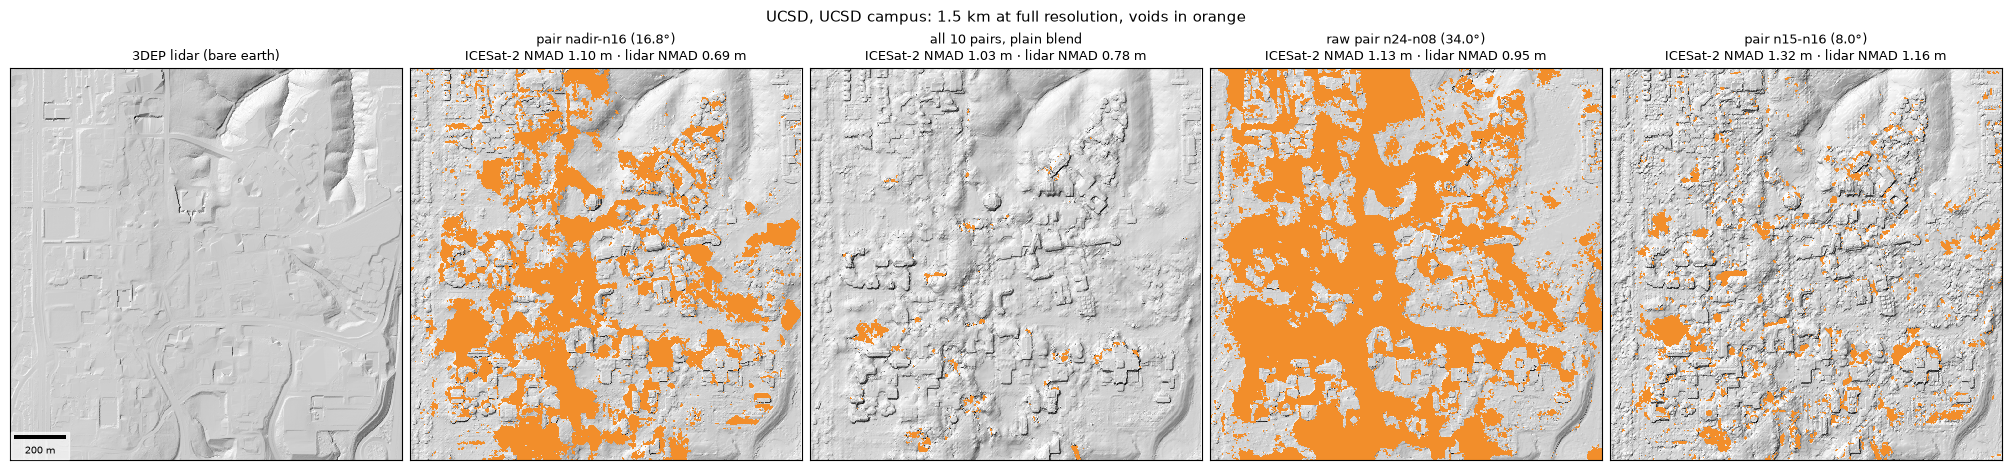

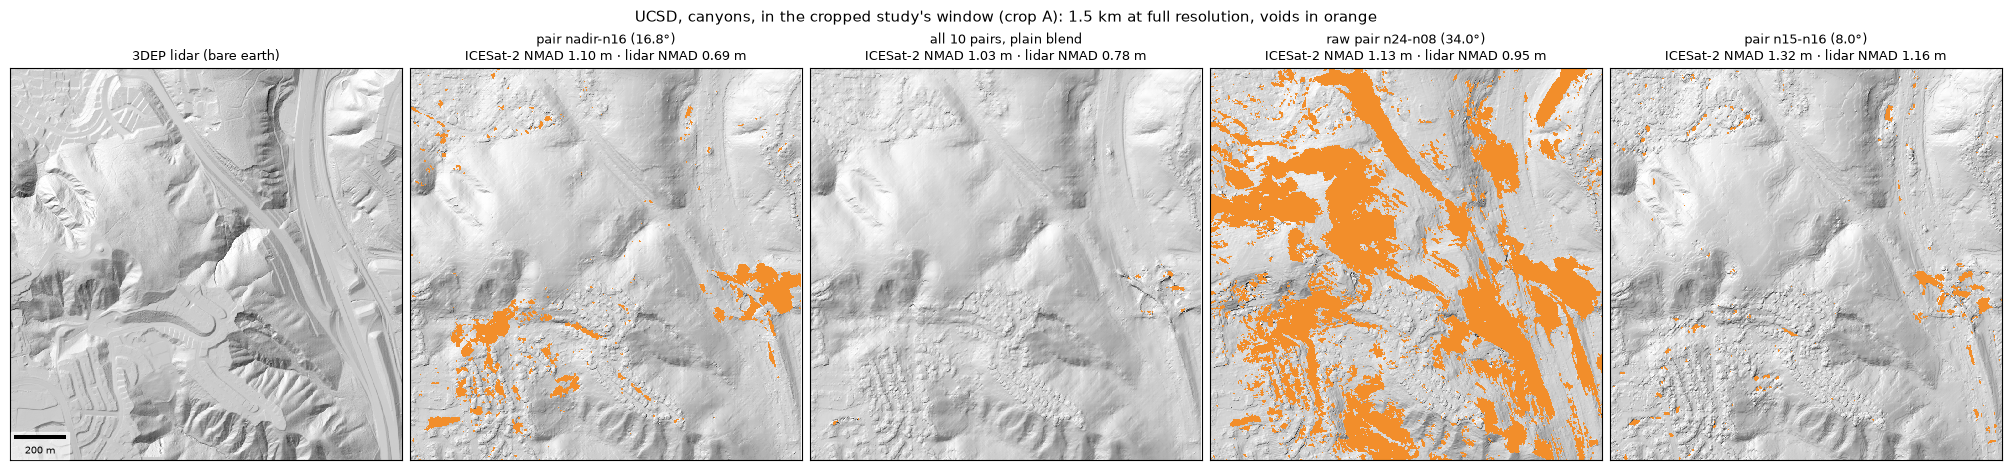

In [5]:
for wname in SITES["UCSD"]["windows"]:
    detail("UCSD", wname)

### Terrain: slope and land cover

**Slope** is computed with Horn's method, the same as `gdaldem slope`, on the lidar site grid (1.9 m at Atlanta, 1.2 m at UCSD). Each DEM is resampled onto that grid (bilinear, after its registration shift), and every distribution is taken over the same cells: land (WorldCover water dropped) where the lidar and all four DEMs are valid.
- The lidar's slope is the terrain's: bare earth.
- A DEM's slope is the surface's: building walls and tree crowns add steep cells, and noise adds steepness everywhere. So the gap between a DEM's curve and the lidar's is partly real surface, partly noise.

These are only the cells all four DEMs cover, so each site's least complete DEM sets the area: Atlanta's raw 10-21 leaves out much of downtown and patches of forest, UCSD's raw n24-n08 much of the campus and the canyon walls. The distributions describe the ground every DEM could map, not the hardest ground.

**Land cover** is ESA WorldCover 2021 over the same cells, next to the share of the benchmark's ICESat-2 points on each class inside that area. The ICESat-2 benchmarks score *stable terrain* (water and trees dropped); the lidar comparison scores *open ground* (shrub, grass, crop, bare, wetland, moss).

In [6]:
def slope_deg(z, res):
    """Horn (1981) slope in degrees, as gdaldem slope; NaN where a 3 × 3 neighbour is NaN."""
    p = np.pad(z, 1, mode="edge")
    a, b, c = p[:-2, :-2], p[:-2, 1:-1], p[:-2, 2:]
    d, f = p[1:-1, :-2], p[1:-1, 2:]
    g, h, i = p[2:, :-2], p[2:, 1:-1], p[2:, 2:]
    dx = ((c + 2 * f + i) - (a + 2 * d + g)) / (8 * res)
    dy = ((g + 2 * h + i) - (a + 2 * b + c)) / (8 * res)
    return np.degrees(np.arctan(np.hypot(dx, dy))).astype(np.float32)

WC = {10: ("trees", "#006400"), 20: ("shrub", "#ffbb22"), 30: ("grass", "#ffff4c"), 40: ("crop", "#f096ff"),
      50: ("built-up", "#fa0000"), 60: ("bare", "#b4b4b4"), 80: ("water", "#0064c8"), 90: ("wetland", "#0096a0"),
      100: ("moss", "#fae6a0")}
OPEN = [20, 30, 40, 60, 90, 100]
BINS = np.arange(0, 91, 1.0)
CLASSES = [0, 5, 10, 20, 30, 90]

for name, s in SITES.items():
    with rio.open(f"{s['grid']}/lidar.tif") as g:
        lid = read_masked(g); tf, crs, shape, res = g.transform, g.crs, g.shape, g.res[0]
    with rio.open(f"{s['grid']}/worldcover.tif") as g:
        wc = g.read(1)
    with rio.open(f"{s['grid']}/slope.tif") as g:
        lid_slope = read_masked(g)
    common = np.isfinite(lid) & np.isfinite(lid_slope) & (wc != 80)
    dem_slope = {}
    for label in s["picks"]:
        fn, de, dn = dem_source(s, label)
        z = np.full(shape, np.nan, np.float32)
        with rio.open(fn) as ds:
            src_tf = ds.transform * rio.Affine.identity()
            src_tf = rio.Affine(src_tf.a, src_tf.b, src_tf.c + de, src_tf.d, src_tf.e, src_tf.f + dn)
            reproject(rio.band(ds, 1), z, src_transform=src_tf, src_crs=ds.crs, dst_transform=tf, dst_crs=crs,
                      resampling=Resampling.bilinear, src_nodata=ds.nodata, dst_nodata=np.nan)
        dem_slope[label] = slope_deg(z, res); del z
        common &= np.isfinite(dem_slope[label])
    s["common_km2"] = common.sum() * res**2 / 1e6
    s["slope_hist"] = {"lidar": np.histogram(lid_slope[common], BINS)[0]}
    s["slope_classes"] = {"3DEP lidar, all land": np.histogram(lid_slope[common], CLASSES)[0],
                          "3DEP lidar, open ground": np.histogram(lid_slope[common & np.isin(wc, OPEN)], CLASSES)[0]}
    for label, sl in dem_slope.items():
        s["slope_hist"][label] = np.histogram(sl[common], BINS)[0]
        s["slope_classes"][s["picks"][label]] = np.histogram(sl[common], CLASSES)[0]
    del dem_slope
    # land cover over the common cells, and the ICESat-2 sample inside them
    s["wc_area"] = pd.Series({c: int((common & (wc == c)).sum()) for c in WC})
    pts = gpd.read_parquet(f"{s['fb']}/atl06sr_all.parquet", columns=["geometry", "esa_worldcover.value"]).to_crs(crs)
    rows, cols = rio.transform.rowcol(tf, pts.geometry.x.values, pts.geometry.y.values)
    rows, cols = np.asarray(rows), np.asarray(cols)
    inside = (rows >= 0) & (rows < shape[0]) & (cols >= 0) & (cols < shape[1])
    inside[inside] = common[rows[inside], cols[inside]]
    s["wc_points"] = pts.loc[inside, "esa_worldcover.value"].astype(int).value_counts().reindex(list(WC), fill_value=0)
    print(f"{name}: {s['common_km2']:.0f} km² of land common to the lidar and the four DEMs; "
          f"{inside.sum():,} of {len(pts):,} ICESat-2 points fall inside it")
    del lid, wc, lid_slope, common

tab = pd.concat({n: pd.DataFrame(s["slope_classes"], index=[f"{a}–{b}°" for a, b in zip(CLASSES[:-1], CLASSES[1:])])
                 for n, s in SITES.items()}, axis=1)
(100 * tab / tab.sum()).T.round(1).rename_axis(["site", "surface"]).style.format("{:.1f}").set_caption(
    "share of the common land area in each slope class (%)")

Atlanta: 357 km² of land common to the lidar and the four DEMs; 87,771 of 154,424 ICESat-2 points fall inside it


UCSD: 104 km² of land common to the lidar and the four DEMs; 19,771 of 63,624 ICESat-2 points fall inside it


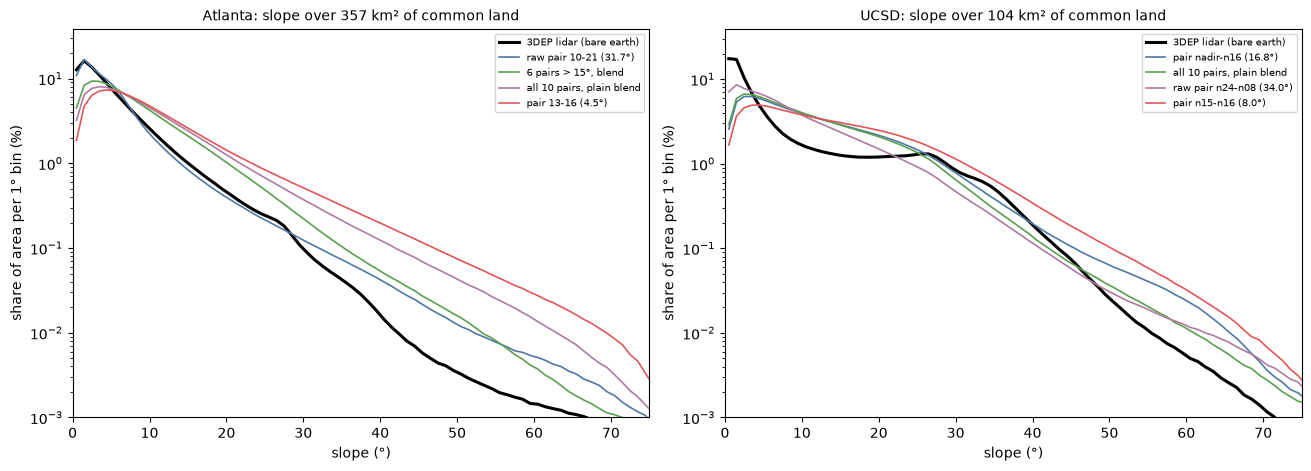

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
x = BINS[:-1] + 0.5
for ax, (name, s) in zip(axs, SITES.items()):
    h = s["slope_hist"]
    ax.plot(x, 100 * h["lidar"] / h["lidar"].sum(), c="k", lw=2.2, label="3DEP lidar (bare earth)")
    for (label, dem_name), c in zip(s["picks"].items(), ["#4e79a7", "#59a14f", "#b07aa1", "#e15759"]):
        ax.plot(x, 100 * h[label] / h[label].sum(), c=c, lw=1.2, label=dem_name)
    ax.set_yscale("log"); ax.set_xlim(0, 75); ax.set_ylim(1e-3, None)
    ax.set_xlabel("slope (°)"); ax.set_ylabel("share of area per 1° bin (%)")
    ax.set_title(f"{name}: slope over {s['common_km2']:.0f} km² of common land", fontsize=10); ax.legend(fontsize=7)

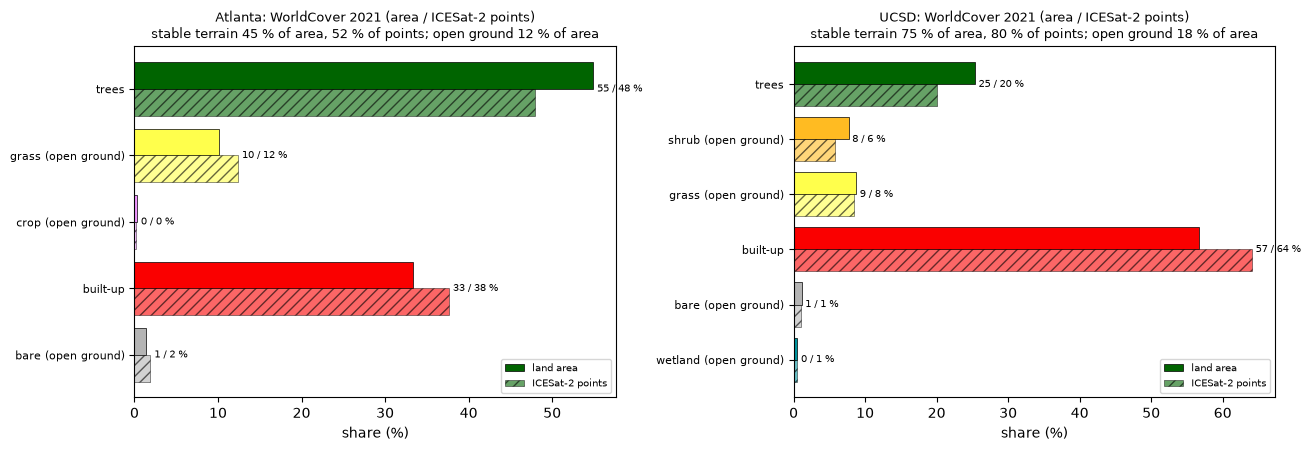

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
for ax, (name, s) in zip(axs, SITES.items()):
    area = 100 * s["wc_area"] / s["wc_area"].sum(); pts = 100 * s["wc_points"] / s["wc_points"].sum()
    keep = [c for c in WC if area[c] >= 0.05 or pts[c] >= 0.05]
    y = np.arange(len(keep))
    ax.barh(y - 0.2, area[keep], 0.4, color=[WC[c][1] for c in keep], ec="k", lw=0.5, label="land area")
    ax.barh(y + 0.2, pts[keep], 0.4, color=[WC[c][1] for c in keep], ec="k", lw=0.5, hatch="///", alpha=0.6,
            label="ICESat-2 points")
    ax.set_yticks(y); ax.set_yticklabels([WC[c][0] + (" (open ground)" if c in OPEN else "") for c in keep], fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel("share (%)")
    for yi, c in zip(y, keep):
        ax.text(max(area[c], pts[c]) + 0.5, yi, f"{area[c]:.0f} / {pts[c]:.0f} %", va="center", fontsize=7)
    stable = 100 - area[[10, 80]].sum(); stable_p = 100 - pts[[10, 80]].sum()
    ax.set_title(f"{name}: WorldCover 2021 (area / ICESat-2 points)\nstable terrain {stable:.0f} % of area, "
                 f"{stable_p:.0f} % of points; open ground {area[OPEN].sum():.0f} % of area", fontsize=9)
    ax.legend(fontsize=7, loc="lower right")

### Key takeaways

1. **The best-scoring DEMs are also the least complete.** NMAD scores only the cells a DEM has, and the wide pairs skip the hardest ground.
    - **Atlanta:** raw pair 10-21, best on both references, has 7.9 % voids inside its footprint. It loses most of downtown, where tall buildings occlude one image of a 32° pair, and patches of forest. The blends and the narrow pair have 0.2–0.8 %.
    - **UCSD:** raw pair n24-n08 (34°) has 12.1 % voids, on the campus and along the canyon walls. Pair nadir-n16, best on the lidar, has 3.5 %, mostly on the campus. The plain 10-pair blend has 0.2 %.
    - So "best DEM" and "best map" are different questions. At Atlanta the > 15° blend (0.8 % voids) costs 0.10 m (ICESat-2) to 0.15 m (lidar) of NMAD against the best pair. At UCSD the 10-pair blend (0.2 % voids) is the best DEM on ICESat-2 and 0.09 m behind the best on the lidar.
2. **Noise from narrow pairs is visible, and it shows up as slope.** In the full-scene hillshades, Atlanta's texture coarsens from the raw 31.7° pair through the blends to the 4.5° pair, matching the order of their NMADs. On Atlanta's common land, slopes of 10–20° cover:

    | surface | share of area at 10–20° |
    |---|---|
    | bare-earth lidar | 11.7 % |
    | best pair | 9.8 % |
    | > 15° blend | 22.7 % |
    | plain 10-pair blend | 25.8 % |
    | 4.5° pair | 27.7 % |

    Slopes above 20° grow from 3.1 % (lidar) to 14.1 % (4.5° pair). At UCSD, on the same cells, the 8° pair has the most ground above 30° (9.6 %) and the raw 34° pair the least (3.5 %).
3. **Averaging all ten pairs fills holes but keeps the narrow pairs' noise.** Atlanta's plain blend is the most complete DEM downtown but visibly rougher than the > 15° blend everywhere. At UCSD the difference is subtler, consistent with the small NMAD gaps there.
4. **One stereo tile failed in raw pair 10-21.** It leaves a square void about 1 km on a side in the southwest of the Atlanta strip. That is the size of one 2048-pixel tile at 0.5 m, so most likely a correlation tile that produced no output. It counts towards that DEM's 7.9 % voids.
5. **The two sites' terrain differs in the ways that matter for scoring.**
    - **Atlanta** is gentle: 85 % of its common land is below 10° on the lidar. It is 55 % trees, 33 % built-up and 12 % open ground. Almost half of the ICESat-2 points fall on trees (48 %), which is why stable-terrain scoring keeps only 52 % of them. The images are from 22 December, when the deciduous canopy is bare. That may be why the best pair's slope distribution follows the bare-earth lidar's so closely below 25°.
    - **UCSD** is steep and urban. On the lidar, 18 % of its common land is above 20°, and 28 % of its open ground. It is 57 % built-up, 25 % trees and 18 % open ground, and 64 % of the ICESat-2 points are on built-up ground. So the ICESat-2 benchmark there mostly scores rooftops and streets, and the lidar comparison only open ground. That is a large part of why the two rank UCSD's DEMs differently.
6. **The lidar is not the surface the DEMs should reproduce.** It is bare earth, from 2014 at UCSD and 2018–20 at Atlanta, so buildings and trees are missing from it by design. The detail windows show the ground the DEMs stand on, which makes buildings, trees and voids easy to see.

**Caveats.**
- The slope and land-cover statistics cover only land that all four DEMs of a site map. They leave out the voids of the least complete DEM, the hardest ground.
- Void shares count holes inside each DEM's footprint. Voids that reach the footprint's edge are not counted, so these are lower bounds.
- Each DEM is moved by its lidar registration shift, not resampled, so the panels of a window line up to about a metre.
